# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [1]:
# Replace None with your code
# Imports
import sqlite3
import pandas as pd

# Create connection to database
conn = sqlite3.connect('data.sqlite')

### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [2]:
# Replace None with your code
pd.read_sql_query("""
SELECT *
FROM customers
WHERE state = 'CA'
AND CAST(creditLimit AS REAL) > 25000;
""", conn)

,customerNumber,customerName,contactLastName,contactFirstName,phone,addressLine1,addressLine2,city,state,postalCode,country,salesRepEmployeeNumber,creditLimit
0,124,Mini Gifts Distributors Ltd.,Nelson,Susan,4155551450,5677 Strong St.,,San Rafael,CA,97562,USA,1165,210500.00
1,129,Mini Wheels Co.,Murphy,Julie,6505555787,5557 North Pendale Street,,San Francisco,CA,94217,USA,1165,64600.00
2,161,Technics Stores Inc.,Hashimoto,Juri,6505556809,9408 Furth Circle,,Burlingame,CA,94217,USA,1165,84600.00
3,205,Toys4GrownUps.com,Young,Julie,6265557265,78934 Hillside Dr.,,Pasadena,CA,90003,USA,1166,90700.00
4,239,Collectable Mini Designs Co.,Thompson,Valarie,7605558146,361 Furth Circle,,San Diego,CA,91217,USA,1166,105000.00
5,321,Corporate Gift Ideas Co.,Brown,Julie,6505551386,7734 Strong St.,,San Francisco,CA,94217,USA,1165,105000.00
6,347,"Men 'R' US Retailers, Ltd.",Chandler,Brian,2155554369,6047 Douglas Av.,,Los Angeles,CA,91003,USA,1166,57700.00
7,450,The Sharp Gifts Warehouse,Frick,Sue,4085553659,3086 Ingle Ln.,,San Jose,CA,94217,USA,1165,77600.00
8,475,West Coast Collectables Co.,Thompson,Steve,3105553722,3675 Furth Circle,,Burbank,CA,94019,USA,1166,55400.00
9,487,Signal Collectibles Ltd.,Taylor,Sue,4155554312,2793 Furth Circle,,Brisbane,CA,94217,USA,1165,60300.00


### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [3]:
# Replace None with your code
collect_customers = pd.read_sql_query("""
SELECT *
FROM customers
WHERE country != 'USA'
AND customerName LIKE '%Collect%';
""", conn)

In [4]:
collect_customers

,customerNumber,customerName,contactLastName,contactFirstName,phone,addressLine1,addressLine2,city,state,postalCode,country,salesRepEmployeeNumber,creditLimit
0,114,"Australian Collectors, Co.",Ferguson,Peter,03 9520 4555,636 St Kilda Road,Level 3,Melbourne,Victoria,3004,Australia,1611,117300.00
1,189,"Clover Collections, Co.",Cassidy,Dean,+353 1862 1555,25 Maiden Lane,Floor No. 4,Dublin,,2,Ireland,1504,69400.00
2,201,"UK Collectables, Ltd.",Devon,Elizabeth,(171) 555-2282,"12, Berkeley Gardens Blvd",,Liverpool,,WX1 6LT,UK,1501,92700.00
3,211,"King Kong Collectables, Co.",Gao,Mike,+852 2251 1555,Bank of China Tower,1 Garden Road,Central Hong Kong,,,Hong Kong,1621,58600.00
4,227,Heintze Collectables,Ibsen,Palle,86 21 3555,Smagsloget 45,,Århus,,8200,Denmark,1401,120800.00
5,260,"Royal Canadian Collectables, Ltd.",Lincoln,Elizabeth,(604) 555-4555,23 Tsawassen Blvd.,,Tsawassen,BC,T2F 8M4,Canada,1323,89600.00
6,293,BG&E Collectables,Harrison,Ed,+41 26 425 50 01,Rte des Arsenaux 41,,Fribourg,,1700,Switzerland,,0.00
7,353,Reims Collectables,Henriot,Paul,26.47.1555,59 rue de l'Abbaye,,Reims,,51100,France,1337,81100.00
8,376,Precious Collectables,Urs,Braun,0452-076555,Hauptstr. 29,,Bern,,3012,Switzerland,1702,0.00
9,382,Salzburg Collectables,Pipps,Georg,6562-9555,Geislweg 14,,Salzburg,,5020,Austria,1401,71700.00


## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

The WHERE clause filters the customers to include only those outside the USA whose names contain “Collect”. 
The != operator excludes customers from the USA, while LIKE '%Collect%' finds customer names containing “Collect” anywhere in the name. 
The AND operator ensures that both conditions must be met, so only customers matching both requirements are returned.

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [ ]:
# Calculate the average customer credit limit for each US state.
# Group customers by state and sort the averages from highest to lowest.
state_credit_limits = pd.read_sql_query("""
SELECT state, AVG(CAST(creditLimit AS REAL)) AS average_credit_limit
FROM customers
WHERE country = 'USA'
GROUP BY state
ORDER BY average_credit_limit DESC;
""", conn)

state_credit_limits

,state,average_credit_limit
0,NH,114200.000000
1,NY,89966.666667
2,PA,84766.666667
3,CA,83854.545455
4,NV,71800.000000
5,MA,70755.555556
6,CT,57350.000000
7,NJ,43000.000000


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

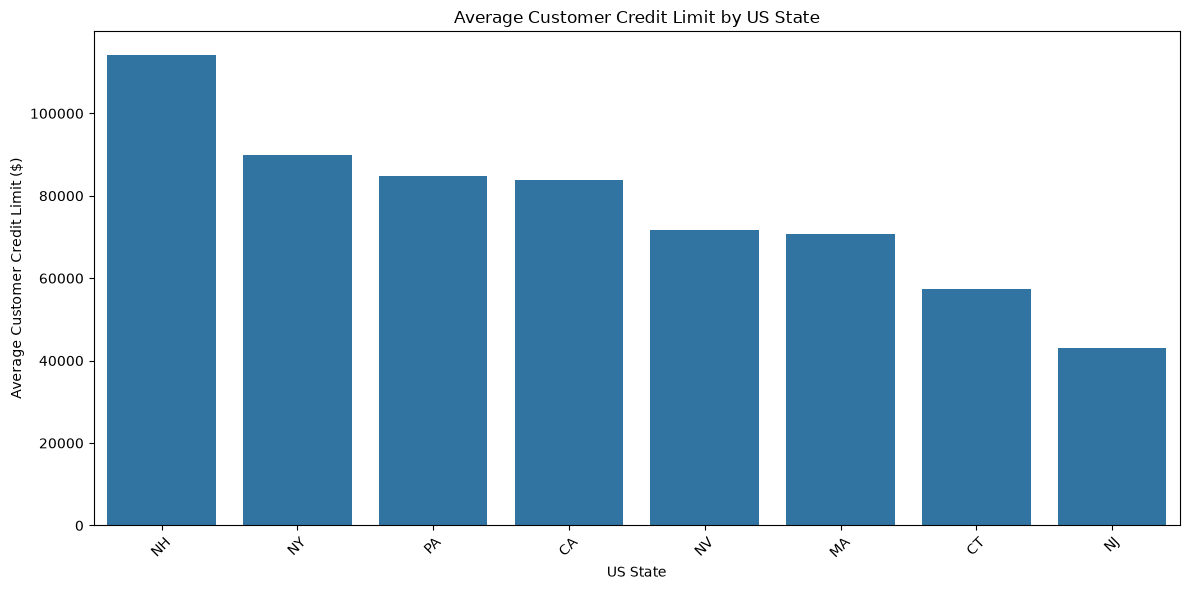

In [6]:
# Replace None with your visual code
# Produce a visual to represent the average credit limit by state
# Import plotting libraries to visualise the average credit limit by state.
import matplotlib.pyplot as plt
import seaborn as sns

# Create a bar chart to compare average credit limits across US states.
plt.figure(figsize=(12, 6))
sns.barplot(data=state_credit_limits, x='state', y='average_credit_limit')

# Add a descriptive title and axis labels.
plt.title('Average Customer Credit Limit by US State')
plt.xlabel('US State')
plt.ylabel('Average Customer Credit Limit ($)')

# Rotate state labels for readability and adjust the chart layout.
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [ ]:
# Calculate the total payments made by each customer and return the top 10.
# Join customers to payments, group payments by customer, and rank totals from highest to lowest.
top_customers = pd.read_sql_query("""
SELECT
    customers.customerNumber,
    customers.customerName,
    SUM(payments.amount) AS total_payments
FROM customers
JOIN payments
    ON customers.customerNumber = payments.customerNumber
GROUP BY customers.customerNumber, customers.customerName
ORDER BY total_payments DESC
LIMIT 10;
""", conn)

top_customers

,customerNumber,customerName,total_payments
0,141,Euro+ Shopping Channel,715738.98
1,124,Mini Gifts Distributors Ltd.,584188.24
2,114,"Australian Collectors, Co.",180585.07
3,151,Muscle Machine Inc,177913.95
4,148,"Dragon Souveniers, Ltd.",156251.03
5,323,"Down Under Souveniers, Inc",154622.08
6,187,"AV Stores, Co.",148410.09
7,276,"Anna's Decorations, Ltd",137034.22
8,321,Corporate Gift Ideas Co.,132340.78
9,146,"Saveley & Henriot, Co.",130305.35


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

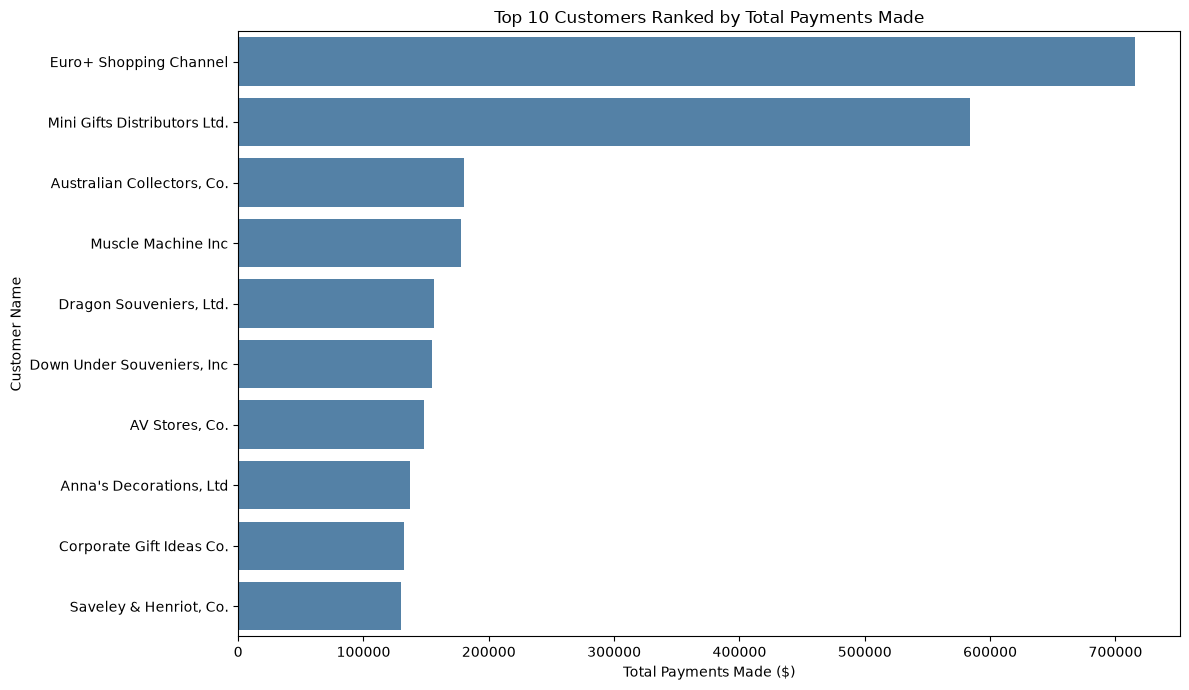

In [11]:
# Replace None with your visual code
# Produce a visual to represent the top ten customers in terms of total payments
# Plot the top 10 customers by total payments, showing the largest total at the top.
plt.figure(figsize=(12, 7))
sns.barplot(
    data=top_customers,
    x='total_payments',
    y='customerName',
    color='steelblue'
)

# Add a descriptive title and labels.
plt.title('Top 10 Customers Ranked by Total Payments Made')
plt.xlabel('Total Payments Made ($)')
plt.ylabel('Customer Name')

# Adjust spacing and display the chart.
plt.tight_layout()
plt.show()

### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [9]:
# Replace None with you code
# Retrieve each customer's products where the total quantity purchased is at least 10 units.
# Join customers, orders, order details, and products to connect customers to their purchases.
# Group by customer and product, then sort by total quantity purchased in ascending order.
customer_product_purchases = pd.read_sql_query("""
SELECT
    customers.customerNumber,
    customers.customerName,
    products.productCode,
    products.productName,
    SUM(orderdetails.quantityOrdered) AS total_quantity_purchased
FROM customers
JOIN orders
    ON customers.customerNumber = orders.customerNumber
JOIN orderdetails
    ON orders.orderNumber = orderdetails.orderNumber
JOIN products
    ON orderdetails.productCode = products.productCode
GROUP BY
    customers.customerNumber,
    customers.customerName,
    products.productCode,
    products.productName
HAVING SUM(orderdetails.quantityOrdered) >= 10
ORDER BY total_quantity_purchased ASC;
""", conn)

customer_product_purchases

,customerNumber,customerName,productCode,productName,total_quantity_purchased
0,314,Petit Auto,S18_2949,1913 Ford Model T Speedster,10
1,412,"Extreme Desk Decorations, Ltd",S24_4620,1961 Chevrolet Impala,10
2,119,La Rochelle Gifts,S32_2509,1954 Greyhound Scenicruiser,11
3,328,Tekni Collectables Inc.,S700_1691,American Airlines: B767-300,11
4,450,The Sharp Gifts Warehouse,S24_3191,1969 Chevrolet Camaro Z28,13
...,...,...,...,...,...
2526,141,Euro+ Shopping Channel,S24_3432,2002 Chevy Corvette,174
2527,141,Euro+ Shopping Channel,S12_4473,1957 Chevy Pickup,183
2528,141,Euro+ Shopping Channel,S24_1444,1970 Dodge Coronet,197
2529,141,Euro+ Shopping Channel,S24_2840,1958 Chevy Corvette Limited Edition,245


### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [10]:
# Replace None with your code
# Calculate the total quantity ordered and the number of distinct products in each product line.
# Join products to order details to measure product variety and customer demand.
product_line_analysis = pd.read_sql_query("""
SELECT
    products.productLine,
    COUNT(DISTINCT products.productCode) AS number_of_products,
    SUM(orderdetails.quantityOrdered) AS total_quantity_ordered
FROM products
JOIN orderdetails
    ON products.productCode = orderdetails.productCode
GROUP BY products.productLine
ORDER BY total_quantity_ordered DESC;
""", conn)

product_line_analysis

,productLine,number_of_products,total_quantity_ordered
0,Classic Cars,37,35582
1,Vintage Cars,24,22933
2,Motorcycles,13,12778
3,Planes,12,11872
4,Trucks and Buses,11,11001
5,Ships,9,8532
6,Trains,3,2818


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

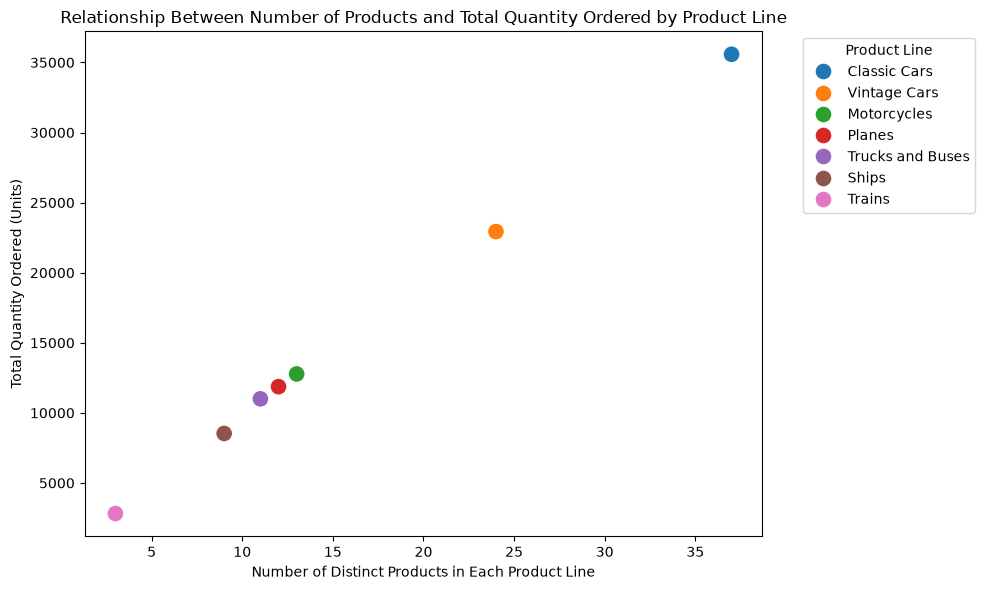

In [12]:
# Replace None with your visual code
# Produce a visual to represent the the relation between number of products and the total amount ordered
# Compare the number of products with the total quantity ordered for each product line.
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=product_line_analysis,
    x='number_of_products',
    y='total_quantity_ordered',
    hue='productLine',
    s=150
)

# Add a descriptive title and axis labels.
plt.title('Relationship Between Number of Products and Total Quantity Ordered by Product Line')
plt.xlabel('Number of Distinct Products in Each Product Line')
plt.ylabel('Total Quantity Ordered (Units)')

# Place the legend outside the chart and display the visualisation.
plt.legend(title='Product Line', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

I used a scatter plot because it makes it easy to see the relationship between the number of products in each product line and the total quantity ordered. 
Each point represents a product line, allowing us to compare product variety with customer demand.

The visual shows that product lines with more products generally have higher total quantities ordered. 
For example, Classic Cars has the most products and the highest quantity ordered, while Trains has the fewest products and the lowest quantity ordered. 

This suggests that product variety may be associated with higher demand. 

However, the chart does not prove that having more products directly causes more orders.
This is because other factors may also be influencing customer purchases.

### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [13]:
# Replace None with your code
# Find employees in offices with fewer than 5 employees, including their job titles and supervisors.
# Identify small offices, then join employees to their supervisors.
small_office_employees = pd.read_sql_query("""
SELECT
    e.employeeNumber,
    e.firstName,
    e.lastName,
    e.jobTitle,
    o.officeCode,
    o.city AS office_city,
    o.country AS office_country,
    s.firstName AS supervisor_first_name,
    s.lastName AS supervisor_last_name
FROM employees AS e
JOIN offices AS o
    ON e.officeCode = o.officeCode
LEFT JOIN employees AS s
    ON e.reportsTo = s.employeeNumber
WHERE e.officeCode IN (
    SELECT officeCode
    FROM employees
    GROUP BY officeCode
    HAVING COUNT(*) < 5
)
ORDER BY e.officeCode, e.lastName;
""", conn)

small_office_employees

,employeeNumber,firstName,lastName,jobTitle,officeCode,office_city,office_country,supervisor_first_name,supervisor_last_name
0,1188,Julie,Firrelli,Sales Rep,2,Boston,USA,Anthony,Bow
1,1216,Steve,Patterson,Sales Rep,2,Boston,USA,Anthony,Bow
2,1286,Foon Yue,Tseng,Sales Rep,3,NYC,USA,Anthony,Bow
3,1323,George,Vanauf,Sales Rep,3,NYC,USA,Anthony,Bow
4,1625,Yoshimi,Kato,Sales Rep,5,Tokyo,Japan,Mami,Nishi
5,1621,Mami,Nishi,Sales Rep,5,Tokyo,Japan,Mary,Patterson
6,1611,Andy,Fixter,Sales Rep,6,Sydney,Australia,William,Patterson
7,1619,Tom,King,Sales Rep,6,Sydney,Australia,William,Patterson
8,1612,Peter,Marsh,Sales Rep,6,Sydney,Australia,William,Patterson
9,1088,William,Patterson,Sales Manager (APAC),6,Sydney,Australia,Mary,Patterson


## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

I used a subquery to first identify offices with fewer than five employees. 
I then grouped the employees by officeCode and used HAVING COUNT(*) < 5 to select only offices that met this condition. 
The main query then used WHERE e.officeCode IN (...) to retrieve employees working in those offices. 
I also joined the employees table to itself to obtain each employee's supervisor and joined the offices table to include office locations. 
This approach ensures that the results contain the required employee information only for offices with fewer than five employees.

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [14]:
# Close the connection to the SQLite database now that all queries are complete.
conn.close()

### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [15]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

# Part 2: Independent Data Analysis

## Introduction

This analysis explores IMDb movie data for the period 2010–2019 to investigate how movie genres differ in representation, average ratings, and recorded voting activity.

Using SQL to retrieve data and Python to clean, analyse, and visualise it, the analysis examines genre patterns and changes over time to identify meaningful trends in the dataset.

## Research Question

How do movie genres differ in their representation, average IMDb ratings, and average vote counts from 2010 to 2019?

## 1. Data Exploration

In [17]:
# View five movie records to understand the available columns and values.
movie_sample = pd.read_sql_query("""
SELECT *
FROM movie_basics
LIMIT 5;
""", conn4)

movie_sample

,movie_id,primary_title,original_title,start_year,runtime_minutes,genres
0,tt0063540,Sunghursh,Sunghursh,2013,175.0,"Action,Crime,Drama"
1,tt0066787,One Day Before the Rainy Season,Ashad Ka Ek Din,2019,114.0,"Biography,Drama"
2,tt0069049,The Other Side of the Wind,The Other Side of the Wind,2018,122.0,Drama
3,tt0069204,Sabse Bada Sukh,Sabse Bada Sukh,2018,NaN,"Comedy,Drama"
4,tt0100275,The Wandering Soap Opera,La Telenovela Errante,2017,80.0,"Comedy,Drama,Fantasy"


In [18]:
# Count movies released each year from 2010 through 2019.
movies_by_year = pd.read_sql_query("""
SELECT
    start_year,
    COUNT(*) AS total_movies
FROM movie_basics
WHERE start_year BETWEEN 2010 AND 2019
GROUP BY start_year
ORDER BY start_year;
""", conn4)

movies_by_year

,start_year,total_movies
0,2010,11849
1,2011,12900
2,2012,13787
3,2013,14709
4,2014,15589
5,2015,16243
6,2016,17272
7,2017,17504
8,2018,16849
9,2019,8379


In [19]:
# Check the columns available in the movie ratings table.
ratings_schema = pd.read_sql_query("""
PRAGMA table_info(movie_ratings);
""", conn4)

ratings_schema

,cid,name,type,notnull,dflt_value,pk
0,0,movie_id,TEXT,0,None,0
1,1,averagerating,REAL,0,None,0
2,2,numvotes,INTEGER,0,None,0


In [20]:
# Compare average movie ratings by genre for movies released between 2010 and 2019.
# Exclude missing ratings and movies with fewer than 100 votes.
ratings_by_genre = pd.read_sql_query("""
SELECT
    TRIM(genre.value) AS genre,
    COUNT(*) AS movie_count,
    ROUND(AVG(r.averagerating), 2) AS average_rating,
    ROUND(AVG(r.numvotes), 0) AS average_votes
FROM movie_basics AS m
JOIN movie_ratings AS r
    ON m.movie_id = r.movie_id
JOIN (
    SELECT movie_id, 'Action' AS value FROM movie_basics WHERE genres LIKE '%Action%'
    UNION ALL
    SELECT movie_id, 'Adventure' FROM movie_basics WHERE genres LIKE '%Adventure%'
    UNION ALL
    SELECT movie_id, 'Animation' FROM movie_basics WHERE genres LIKE '%Animation%'
    UNION ALL
    SELECT movie_id, 'Biography' FROM movie_basics WHERE genres LIKE '%Biography%'
    UNION ALL
    SELECT movie_id, 'Comedy' FROM movie_basics WHERE genres LIKE '%Comedy%'
    UNION ALL
    SELECT movie_id, 'Crime' FROM movie_basics WHERE genres LIKE '%Crime%'
    UNION ALL
    SELECT movie_id, 'Documentary' FROM movie_basics WHERE genres LIKE '%Documentary%'
    UNION ALL
    SELECT movie_id, 'Drama' FROM movie_basics WHERE genres LIKE '%Drama%'
    UNION ALL
    SELECT movie_id, 'Family' FROM movie_basics WHERE genres LIKE '%Family%'
    UNION ALL
    SELECT movie_id, 'Fantasy' FROM movie_basics WHERE genres LIKE '%Fantasy%'
    UNION ALL
    SELECT movie_id, 'History' FROM movie_basics WHERE genres LIKE '%History%'
    UNION ALL
    SELECT movie_id, 'Horror' FROM movie_basics WHERE genres LIKE '%Horror%'
    UNION ALL
    SELECT movie_id, 'Music' FROM movie_basics WHERE genres LIKE '%Music%'
    UNION ALL
    SELECT movie_id, 'Musical' FROM movie_basics WHERE genres LIKE '%Musical%'
    UNION ALL
    SELECT movie_id, 'Mystery' FROM movie_basics WHERE genres LIKE '%Mystery%'
    UNION ALL
    SELECT movie_id, 'Romance' FROM movie_basics WHERE genres LIKE '%Romance%'
    UNION ALL
    SELECT movie_id, 'Sci-Fi' FROM movie_basics WHERE genres LIKE '%Sci-Fi%'
    UNION ALL
    SELECT movie_id, 'Sport' FROM movie_basics WHERE genres LIKE '%Sport%'
    UNION ALL
    SELECT movie_id, 'Thriller' FROM movie_basics WHERE genres LIKE '%Thriller%'
    UNION ALL
    SELECT movie_id, 'War' FROM movie_basics WHERE genres LIKE '%War%'
    UNION ALL
    SELECT movie_id, 'Western' FROM movie_basics WHERE genres LIKE '%Western%'
) AS genre
    ON m.movie_id = genre.movie_id
WHERE m.start_year BETWEEN 2010 AND 2019
    AND m.genres IS NOT NULL
    AND r.averagerating IS NOT NULL
    AND r.numvotes >= 100
GROUP BY TRIM(genre.value)
ORDER BY average_rating DESC;
""", conn4)

ratings_by_genre

,genre,movie_count,average_rating,average_votes
0,Documentary,3537,7.09,1250.0
1,Biography,1461,6.88,14752.0
2,History,1007,6.67,7744.0
3,Sport,517,6.60,7230.0
4,Music,942,6.57,7038.0
5,Animation,865,6.31,17718.0
6,War,406,6.26,6582.0
7,Musical,248,6.22,5545.0
8,Drama,13803,6.16,8626.0
9,Romance,3475,5.98,7717.0


In [21]:
# Calculate the average rating and number of rated movies for each year.
ratings_by_year = pd.read_sql_query("""
SELECT
    mb.start_year,
    COUNT(DISTINCT mr.movie_id) AS rated_movie_count,
    ROUND(AVG(mr.averagerating), 2) AS average_rating
FROM movie_basics AS mb
JOIN movie_ratings AS mr
    ON mb.movie_id = mr.movie_id
WHERE mb.start_year BETWEEN 2010 AND 2019
    AND mr.averagerating IS NOT NULL
GROUP BY mb.start_year
ORDER BY mb.start_year;
""", conn4)

ratings_by_year

,start_year,rated_movie_count,average_rating
0,2010,6792,6.26
1,2011,7389,6.29
2,2012,7680,6.30
3,2013,7990,6.29
4,2014,8371,6.32
5,2015,8494,6.27
6,2016,8721,6.35
7,2017,8713,6.40
8,2018,7526,6.42
9,2019,2180,6.70


### Preparing Genre Data

Some movies are assigned multiple genres, separated by commas. We split these combinations and create a separate row for each genre so that each genre can be analysed individually. We also remove extra whitespace from genre names for consistency.

In [22]:
# Retrieve movie counts by genre and release year.
genre_counts_by_year = pd.read_sql_query("""
SELECT
    start_year,
    genres,
    COUNT(DISTINCT movie_id) AS movie_count
FROM movie_basics
WHERE start_year BETWEEN 2010 AND 2019
    AND genres IS NOT NULL
GROUP BY start_year, genres
ORDER BY start_year;
""", conn4)

genre_counts_by_year

,start_year,genres,movie_count
0,2010,Action,158
1,2010,"Action,Adventure",10
2,2010,"Action,Adventure,Animation",11
3,2010,"Action,Adventure,Biography",1
4,2010,"Action,Adventure,Comedy",20
...,...,...,...
5632,2019,Sport,12
5633,2019,Talk-Show,3
5634,2019,Thriller,333
5635,2019,War,11


In [23]:
# Split genre combinations into individual genres.
genre_counts_by_year['genres'] = genre_counts_by_year['genres'].str.split(',')

# Create a separate row for each genre.
genre_counts_by_year = genre_counts_by_year.explode('genres')

# Remove any whitespace around genre names.
genre_counts_by_year['genres'] = genre_counts_by_year['genres'].str.strip()

genre_counts_by_year

,start_year,genres,movie_count
0,2010,Action,158
1,2010,Action,10
1,2010,Adventure,10
2,2010,Action,11
2,2010,Adventure,11
...,...,...,...
5632,2019,Sport,12
5633,2019,Talk-Show,3
5634,2019,Thriller,333
5635,2019,War,11


In [24]:
# Calculate total movie counts for each genre in each year.
genre_year_counts = genre_counts_by_year.groupby(
    ['start_year', 'genres'],
    as_index=False
)['movie_count'].sum()

genre_year_counts

,start_year,genres,movie_count
0,2010,Action,891
1,2010,Adventure,502
2,2010,Animation,198
3,2010,Biography,793
4,2010,Comedy,2179
...,...,...,...
249,2019,Sport,92
250,2019,Talk-Show,3
251,2019,Thriller,847
252,2019,War,57


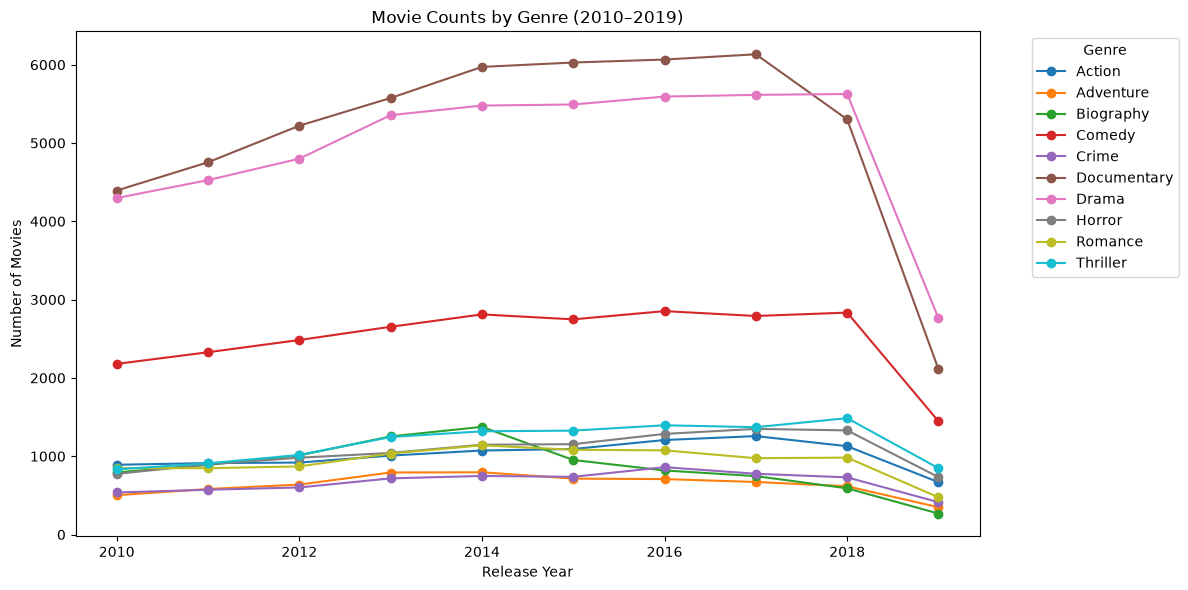

In [25]:
# Identify the 10 genres with the highest movie counts across the decade.
top_genres = genre_year_counts.groupby('genres')['movie_count'].sum().nlargest(10).index

# Filter the data to include only these genres.
top_genre_trends = genre_year_counts[
    genre_year_counts['genres'].isin(top_genres)
]

# Plot movie counts by genre over time.
top_genre_trends.pivot(
    index='start_year',
    columns='genres',
    values='movie_count'
).plot(figsize=(12, 6), marker='o')

plt.title('Movie Counts by Genre (2010–2019)')
plt.xlabel('Release Year')
plt.ylabel('Number of Movies')
plt.legend(title='Genre', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 2. Data Retrieval

We use SQL to retrieve movie IDs, release years, and genres from `movie_basics` for 2010–2019. This provides the data needed to examine genre representation and trends over time.

In [26]:
# Retrieve individual movies and their genres from 2010 to 2019.
movies_by_genre = pd.read_sql_query("""
SELECT
    movie_id,
    start_year,
    genres
FROM movie_basics
WHERE start_year BETWEEN 2010 AND 2019
    AND genres IS NOT NULL;
""", conn4)

## 3. Data Cleaning and Preparation

Movies may have multiple genres stored in one column. We split these genres into separate rows and remove extra spaces so each movie–genre combination can be analysed consistently.

In [27]:
# Split each movie's genres into individual rows.
movies_by_genre['genres'] = movies_by_genre['genres'].str.split(',')

movies_by_genre = movies_by_genre.explode('genres')

movies_by_genre['genres'] = movies_by_genre['genres'].str.strip()

### Yearly Genre Representation

We count distinct movies within each genre and year to examine how genre representation changes over time.

In [28]:
# Count distinct movies within each year and genre.
genre_year_counts = movies_by_genre.groupby(
    ['start_year', 'genres']
)['movie_id'].nunique().reset_index(name='movie_count')

In [29]:
genre_year_counts.head()

,start_year,genres,movie_count
0,2010,Action,891
1,2010,Adventure,502
2,2010,Animation,198
3,2010,Biography,793
4,2010,Comedy,2179


In [30]:
# Count distinct movies in each genre across the decade.
genre_counts = movies_by_genre.groupby('genres')['movie_id'].nunique().sort_values(ascending=False).reset_index(name='movie_count')

genre_counts

,genres,movie_count
0,Documentary,51556
1,Drama,49545
2,Comedy,25127
3,Thriller,11746
4,Horror,10692
5,Action,10156
6,Romance,9327
7,Biography,8695
8,Crime,6691
9,Adventure,6366


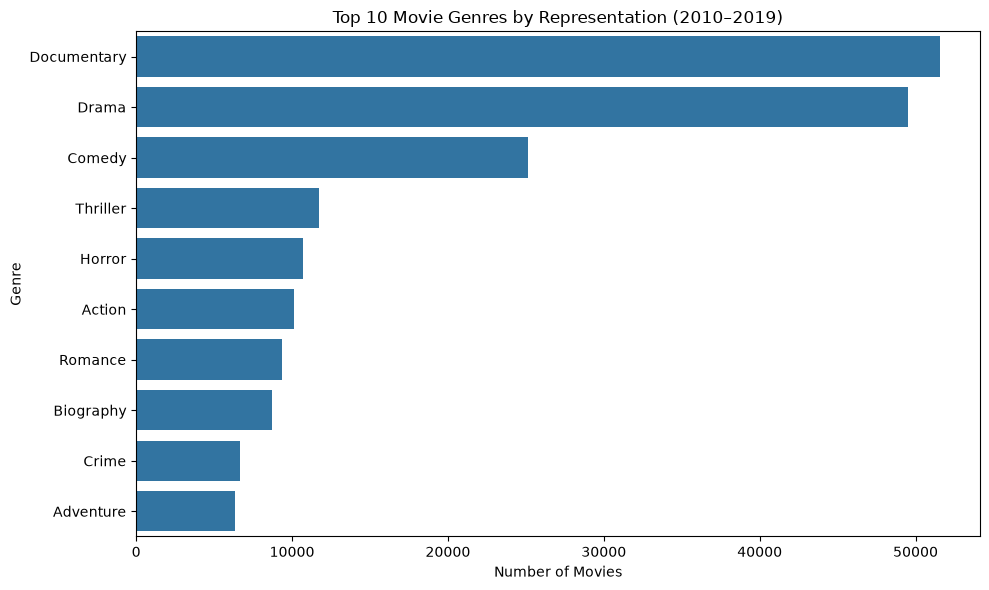

In [31]:
# Visualise the 10 most represented genres.
plt.figure(figsize=(10, 6))

sns.barplot(
    data=genre_counts.head(10),
    x='movie_count',
    y='genres'
)

plt.title('Top 10 Movie Genres by Representation (2010–2019)')
plt.xlabel('Number of Movies')
plt.ylabel('Genre')
plt.tight_layout()
plt.show()

In [32]:
# Arrange genre counts by year for trend analysis.
genre_year_pivot = genre_year_counts.pivot(
    index='start_year',
    columns='genres',
    values='movie_count'
).fillna(0)

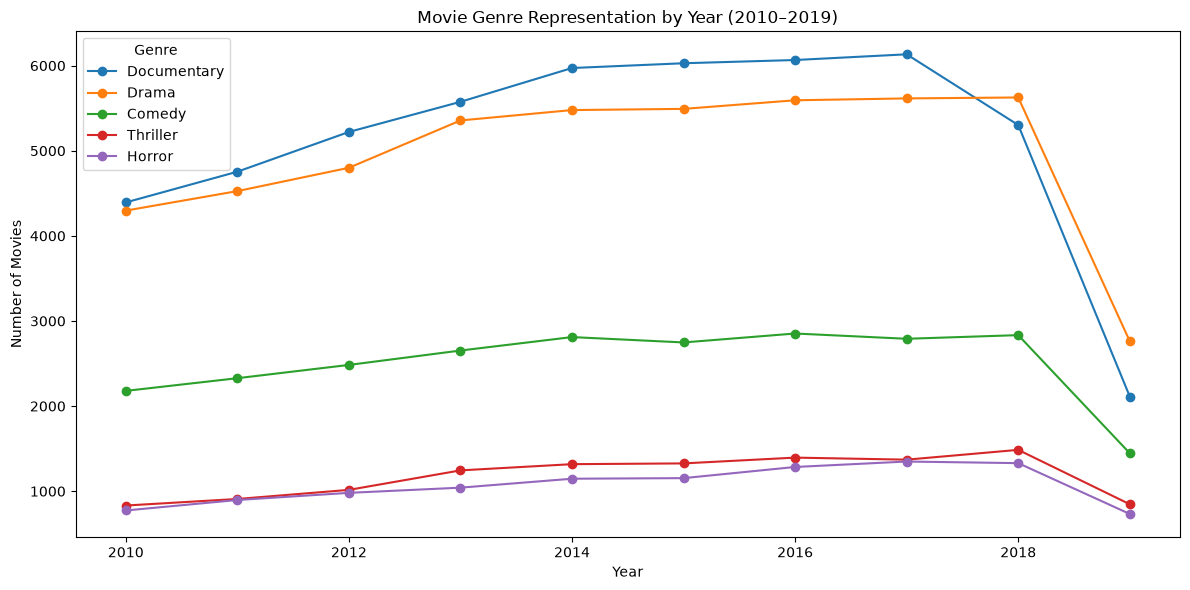

In [33]:
# Plot yearly trends for the five most represented genres.
top_genres = genre_counts.head(5)['genres']

genre_year_pivot[top_genres].plot(figsize=(12, 6), marker='o')

plt.title('Movie Genre Representation by Year (2010–2019)')
plt.xlabel('Year')
plt.ylabel('Number of Movies')
plt.legend(title='Genre')
plt.tight_layout()
plt.show()

**Findings:** Documentary and Drama were the most represented genres in the overall genre dataset. Counts for several major genres increased through much of the decade before dropping sharply in 2019. This decline may reflect incomplete dataset coverage, so it should not be interpreted as proof of an industry-wide decline in movie production.

In [36]:
# List the tables available in the database.
pd.read_sql_query("""
SELECT name
FROM sqlite_master
WHERE type = 'table';
""", conn4)

,name
0,movie_basics
1,directors
2,known_for
3,movie_akas
4,movie_ratings
5,persons
6,principals
7,writers


In [37]:
# Inspect the columns in the ratings table.
pd.read_sql_query("""
PRAGMA table_info(movie_ratings);
""", conn4)

,cid,name,type,notnull,dflt_value,pk
0,0,movie_id,TEXT,0,None,0
1,1,averagerating,REAL,0,None,0
2,2,numvotes,INTEGER,0,None,0


In [38]:
# Retrieve movie genres alongside their IMDb ratings and vote counts.
movies_rated = pd.read_sql_query("""
SELECT
    b.movie_id,
    b.start_year,
    b.genres,
    r.averagerating,
    r.numvotes
FROM movie_basics AS b
JOIN movie_ratings AS r
    ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019
    AND b.genres IS NOT NULL;
""", conn4)

In [39]:
# Split movies into individual genre rows.
movies_rated['genres'] = movies_rated['genres'].str.split(',')

movies_rated = movies_rated.explode('genres')

movies_rated['genres'] = movies_rated['genres'].str.strip()

## Genre Ratings and Voting Activity

We join `movie_basics` with `movie_ratings` to compare movie representation, average IMDb ratings, and recorded votes across genres.

In [40]:
# Summarise movie representation, ratings and voting activity by genre.
genre_analysis = movies_rated.groupby('genres').agg(
    movie_count=('movie_id', 'nunique'),
    average_rating=('averagerating', 'mean'),
    average_votes=('numvotes', 'mean')
).round(2).sort_values('movie_count', ascending=False).reset_index()

genre_analysis

,genres,movie_count,average_rating,average_votes
0,Drama,30788,6.40,3883.57
1,Documentary,17753,7.33,266.96
2,Comedy,17290,6.00,4297.62
3,Thriller,8217,5.64,5860.45
4,Horror,7674,5.00,3112.42
5,Action,6988,5.81,14476.49
6,Romance,6589,6.15,4084.67
7,Crime,4611,6.12,8594.96
8,Adventure,3817,6.20,22067.75
9,Biography,3809,7.16,5673.26


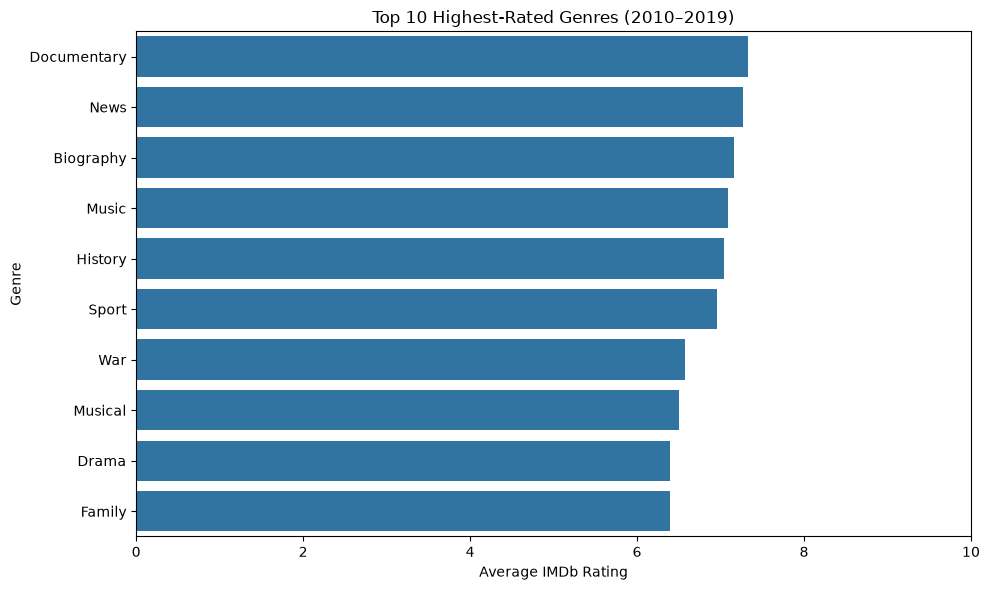

In [41]:
# Compare average ratings for genres with at least 500 rated movies.
top_rated_genres = genre_analysis[
    genre_analysis['movie_count'] >= 500
].sort_values('average_rating', ascending=False).head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_rated_genres,
    x='average_rating',
    y='genres'
)

plt.title('Top 10 Highest-Rated Genres (2010–2019)')
plt.xlabel('Average IMDb Rating')
plt.ylabel('Genre')
plt.xlim(0, 10)
plt.tight_layout()
plt.show()

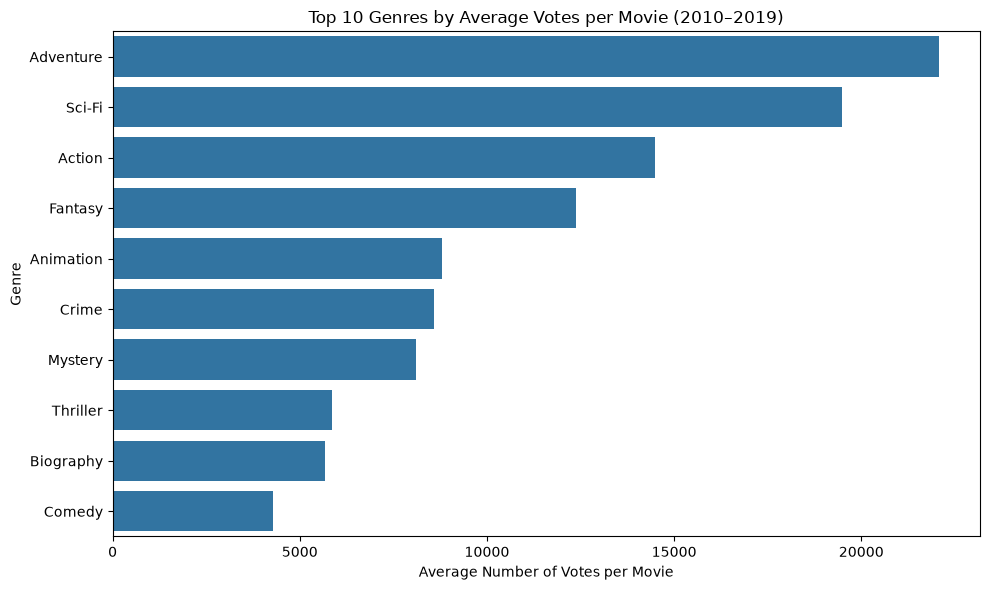

In [42]:
# Compare average voting activity for genres with at least 500 rated movies.
top_voted_genres = genre_analysis[
    genre_analysis['movie_count'] >= 500
].sort_values('average_votes', ascending=False).head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_voted_genres,
    x='average_votes',
    y='genres'
)

plt.title('Top 10 Genres by Average Votes per Movie (2010–2019)')
plt.xlabel('Average Number of Votes per Movie')
plt.ylabel('Genre')
plt.tight_layout()
plt.show()

In [43]:
# Measure the relationship between movie ratings and voting activity.
rating_vote_relationship = movies_rated[['averagerating', 'numvotes']].corr()

rating_vote_relationship

,averagerating,numvotes
averagerating,1.000000,0.059736
numvotes,0.059736,1.000000


In [44]:
# Compare average ratings and voting activity across genres.
genre_comparison = genre_analysis[
    genre_analysis['movie_count'] >= 500
].sort_values('average_rating', ascending=False)

genre_comparison[['genres', 'movie_count', 'average_rating', 'average_votes']]

,genres,movie_count,average_rating,average_votes
1,Documentary,17753,7.33,266.96
20,News,579,7.27,212.99
9,Biography,3809,7.16,5673.26
15,Music,1968,7.09,2771.02
12,History,2825,7.04,2776.41
17,Sport,1179,6.96,3185.60
18,War,853,6.58,3147.39
19,Musical,721,6.50,1925.06
0,Drama,30788,6.40,3883.57
10,Family,3412,6.39,2531.27


## Yearly Trends

We compare movie counts, average ratings, and average votes by year to identify changes between 2010 and 2019.

In [45]:
# Compare average ratings and voting activity by year.
yearly_analysis = movies_rated.groupby('start_year').agg(
    movie_count=('movie_id', 'nunique'),
    average_rating=('averagerating', 'mean'),
    average_votes=('numvotes', 'mean')
).round(2).reset_index()

yearly_analysis

,start_year,movie_count,average_rating,average_votes
0,2010,6701,6.23,6889.10
1,2011,7274,6.27,6644.20
2,2012,7602,6.30,6258.21
3,2013,7905,6.30,6386.05
4,2014,8269,6.34,5864.34
5,2015,8405,6.24,4584.78
6,2016,8613,6.29,4714.28
7,2017,8638,6.32,4058.97
8,2018,7476,6.35,3621.61
9,2019,2169,6.66,2377.85


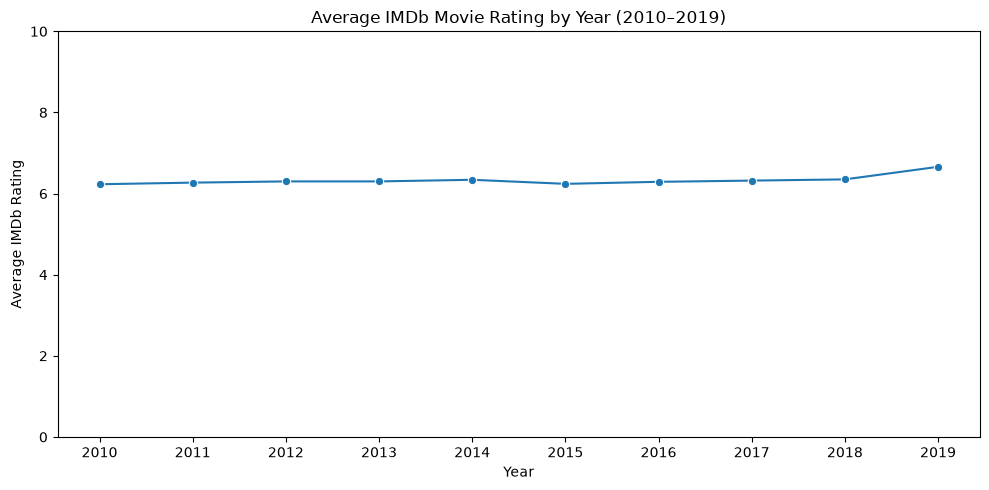

In [46]:
# Visualise average IMDb ratings by year.
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_analysis,
    x='start_year',
    y='average_rating',
    marker='o'
)

plt.title('Average IMDb Movie Rating by Year (2010–2019)')
plt.xlabel('Year')
plt.ylabel('Average IMDb Rating')
plt.xticks(yearly_analysis['start_year'])
plt.ylim(0, 10)
plt.tight_layout()
plt.show()

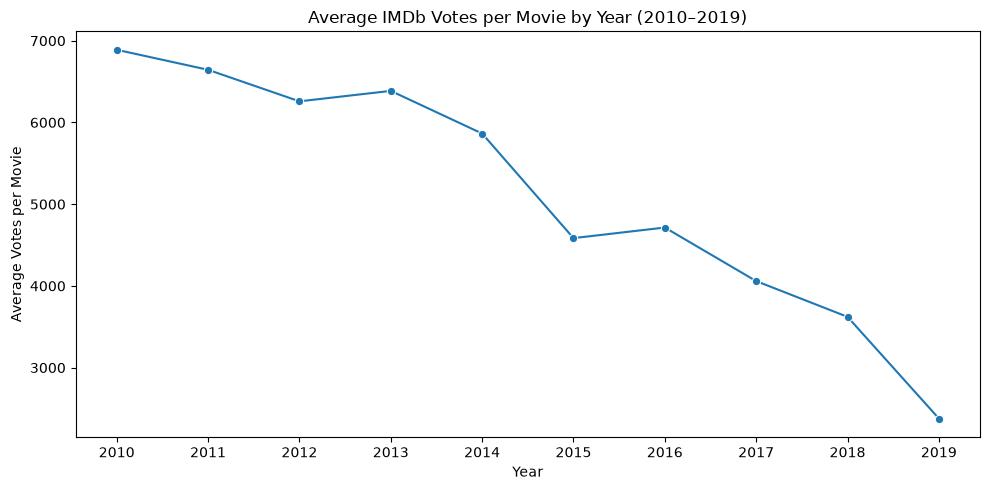

In [47]:
# Visualise average voting activity by year.
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_analysis,
    x='start_year',
    y='average_votes',
    marker='o'
)

plt.title('Average IMDb Votes per Movie by Year (2010–2019)')
plt.xlabel('Year')
plt.ylabel('Average Votes per Movie')
plt.xticks(yearly_analysis['start_year'])
plt.tight_layout()
plt.show()

### Relationship Between Ratings and Votes

We calculate Pearson correlation to assess the strength and direction of the linear relationship between IMDb ratings and recorded vote counts.

In [48]:
# Keep one row per movie before calculating correlation.
movie_level_ratings = movies_rated.drop_duplicates('movie_id')

# Calculate the relationship between ratings and votes.
rating_vote_relationship = movie_level_ratings[
    ['averagerating', 'numvotes']
].corr()

rating_vote_relationship

,averagerating,numvotes
averagerating,1.000000,0.044873
numvotes,0.044873,1.000000


In [49]:
# Retrieve the raw movie data needed for analysis.
movies_rated_raw = pd.read_sql_query("""
SELECT
    b.movie_id,
    b.start_year,
    b.genres,
    r.averagerating,
    r.numvotes
FROM movie_basics AS b
JOIN movie_ratings AS r
    ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019;
""", conn4)

# Remove records missing essential analysis fields.
movies_rated_clean = movies_rated_raw.dropna(
    subset=['movie_id', 'start_year', 'genres', 'averagerating', 'numvotes']
).copy()

# Split movies with multiple genres into separate rows.
movies_rated_clean['genres'] = movies_rated_clean['genres'].str.split(',')
movies_rated_clean = movies_rated_clean.explode('genres')

# Standardise genre names by removing surrounding spaces.
movies_rated_clean['genres'] = movies_rated_clean['genres'].str.strip()

# Remove rows with empty genre labels.
movies_rated_clean = movies_rated_clean[
    movies_rated_clean['genres'] != ''
].copy()

In [50]:
# Keep one row per movie for the yearly analysis.
movie_level_clean = movies_rated_clean.drop_duplicates('movie_id')

# Compare movie counts, ratings and votes by year.
yearly_analysis = movie_level_clean.groupby('start_year').agg(
    movie_count=('movie_id', 'nunique'),
    average_rating=('averagerating', 'mean'),
    average_votes=('numvotes', 'mean')
).round(2).reset_index()

yearly_analysis

,start_year,movie_count,average_rating,average_votes
0,2010,6701,6.26,4549.16
1,2011,7274,6.29,4500.91
2,2012,7602,6.30,4304.80
3,2013,7905,6.29,4508.18
4,2014,8269,6.32,4157.76
5,2015,8405,6.27,3113.14
6,2016,8613,6.34,3090.63
7,2017,8638,6.39,2535.29
8,2018,7476,6.41,2207.30
9,2019,2169,6.70,1415.58


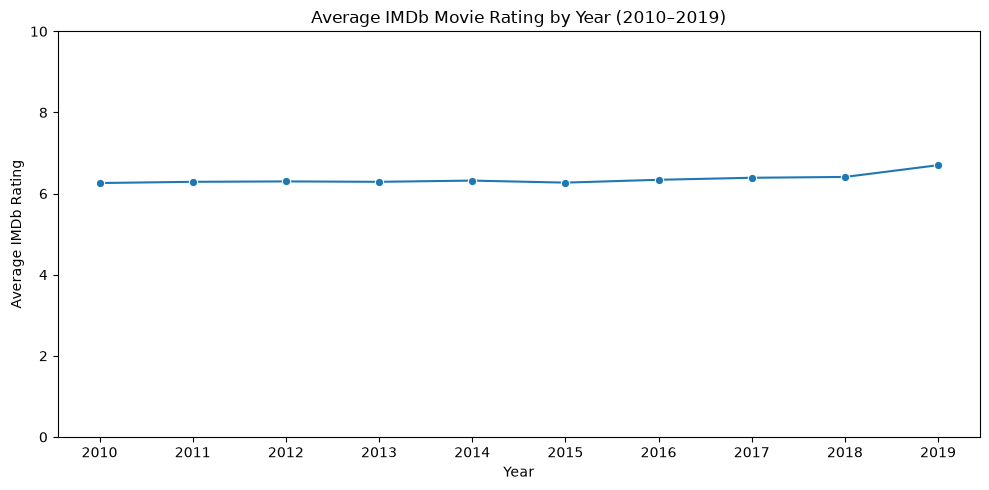

In [51]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_analysis,
    x='start_year',
    y='average_rating',
    marker='o'
)

plt.title('Average IMDb Movie Rating by Year (2010–2019)')
plt.xlabel('Year')
plt.ylabel('Average IMDb Rating')
plt.xticks(yearly_analysis['start_year'])
plt.ylim(0, 10)
plt.tight_layout()
plt.show()

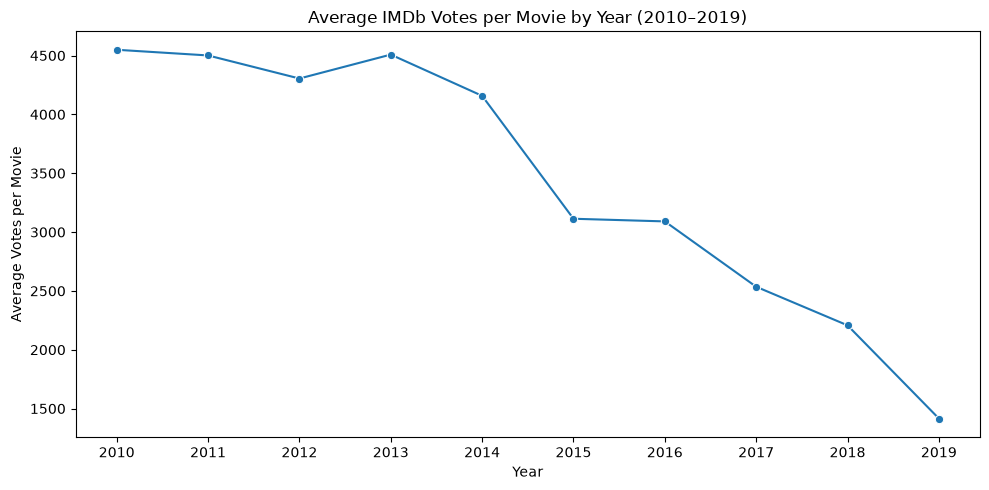

In [52]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_analysis,
    x='start_year',
    y='average_votes',
    marker='o'
)

plt.title('Average IMDb Votes per Movie by Year (2010–2019)')
plt.xlabel('Year')
plt.ylabel('Average Votes per Movie')
plt.xticks(yearly_analysis['start_year'])
plt.tight_layout()
plt.show()

# 9. Overall Findings, Business Implications and Conclusion

## Key Findings

The analysis of IMDb movie data from 2010 to 2019 revealed differences in genre representation, average ratings, and recorded voting activity.

**Genre representation:** Documentary and Drama were the most represented genres in the overall genre dataset. The representation of several major genres increased through much of the decade before declining sharply in 2019. This decline may reflect incomplete dataset coverage rather than an actual reduction in movie production.

**Ratings and audience engagement:** Documentary recorded the highest average rating among genres with at least 500 movies, at 7.33/10, followed by News at 7.27 and Biography at 7.16. Drama had the largest representation in the rated-movie dataset, with 30,788 movies. Adventure and Action recorded relatively high average vote counts per movie, while Horror had the lowest average rating among genres meeting the 500-movie threshold, at 5.00/10.

**Yearly trends:** The number of rated movies peaked at 8,638 in 2017 before falling to 2,169 in 2019. Average ratings remained relatively stable between 6.26 and 6.41 from 2010 to 2018, before rising to 6.70 in 2019. Meanwhile, average votes per movie generally declined from approximately 4,549 in 2010 to 1,416 in 2019.

**Relationship between ratings and votes:** The Pearson correlation coefficient was approximately 0.045, indicating a very weak positive linear relationship between average IMDb ratings and recorded vote counts. This suggests that higher voting activity did not consistently correspond to higher ratings in the dataset.

## Business Implications

The findings offer several insights for stakeholders in the film industry:

- **Producers and investors:** Genre representation and rating patterns can inform initial research into content opportunities. However, these measures should be combined with production costs, revenue, distribution performance, and audience research before investment decisions are made.
- **Marketing and distribution teams:** Genres with relatively high vote counts, such as Adventure and Action, may warrant further investigation into audience engagement and marketing strategies. Recorded votes alone do not establish actual viewership or commercial demand.
- **Content and programming teams:** Genres with high average ratings, such as Documentary and Biography, may merit consideration when developing content portfolios. Ratings should be assessed alongside audience size, target-market preferences, and financial performance.
- **Data-driven decision-making:** Comparing genre representation, ratings, and voting activity provides a more balanced view than relying on a single metric. Further analysis using reliable revenue, budget, streaming, or viewership data would be needed to assess commercial success.

## Limitations

This analysis is limited to the available IMDb dataset. Movies can belong to multiple genres, meaning genre counts overlap. Recorded votes are not equivalent to actual viewership, and average ratings do not measure profitability. The sharp decline in the number of rated movies in 2019 may also affect comparisons with earlier years. Consequently, the findings describe patterns in the available data and should not be treated as definitive evidence of industry-wide production or market trends.

## Conclusion

This project demonstrates how SQL, Python, pandas, and data visualisation can be used to explore a real-world dataset and communicate findings relevant to business decisions. The results show that genre representation, average ratings, and recorded voting activity capture different aspects of movie performance. While these measures can support preliminary research and strategic planning, stronger commercial conclusions require additional financial and audience data.